# Анализ ошибок CatBoost

Цель — найти объекты, для которых предсказанная цена заметно отличается от фактической, и проверить, с какими признаками связаны большие ошибки.

В `X_merged.csv` сначала записаны обучающие объекты, затем отложенная выборка (далее holdout): это порядок конкатенации `X_train` и `X_test` в `model_selection.ipynb` (разбиение 75/25). Предсказания на обучающей части получены на данных, на которых модель обучалась, поэтому они оптимистичны. Основные выводы ниже делаются по holdout.

Знаковая ошибка определяется как `фактическая цена − предсказанная цена`: положительное значение означает недооценку, отрицательное — переоценку. Большой считаем абсолютную ошибку не менее 100 000 — это порог для поиска отдельных сильно ошибочных объектов, а не универсальная граница качества.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
data_path = Path("../data/interim/X_merged.csv")
if not data_path.exists():
    data_path = Path("data/interim/X_merged.csv")
if not data_path.exists():
    raise FileNotFoundError("Не найден data/interim/X_merged.csv")

df = pd.read_csv(data_path)
required_columns = {"y_true", "y_pred_cb", "Square", "Rooms", "DistrictId"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"В данных отсутствуют необходимые столбцы: {sorted(missing_columns)}")

split_at = int(round(len(df) * 0.75))
df["sample"] = np.where(np.arange(len(df)) < split_at, "train (in-sample)", "holdout")
df["error"] = df["y_true"] - df["y_pred_cb"]
df["abs_error"] = df["error"].abs()
df["relative_error_pct"] = df["abs_error"] / df["y_true"].replace(0, np.nan) * 100
df["large_error"] = df["abs_error"] >= 100_000

train = df[df["sample"] == "train (in-sample)"].copy()
holdout = df[df["sample"] == "holdout"].copy()
print(f"Всего объектов: {len(df):,}; train: {len(train):,}; holdout: {len(holdout):,}")

Всего объектов: 10,000; train: 7,500; holdout: 2,500


## Качество на обучающей и отложенной выборках

Сравнение нужно, чтобы не смешивать внутривыборочную точность с оценкой обобщающей способности. MAE и RMSE указаны в единицах цены; смещение — средняя знаковая ошибка.

In [2]:
def summarize_errors(part):
    return pd.Series({
        "n": len(part),
        "MAE": part["abs_error"].mean(),
        "RMSE": np.sqrt(np.mean(part["error"] ** 2)),
        "Медиана |ошибки|": part["abs_error"].median(),
        "Медиана относительной ошибки, %": part["relative_error_pct"].median(),
        "Среднее смещение": part["error"].mean(),
        "Ошибок ≥ 100 000": part["large_error"].sum(),
        "Доля ошибок ≥ 100 000, %": part["large_error"].mean() * 100,
    })

metrics = pd.DataFrame({
    "train (in-sample)": summarize_errors(train),
    "holdout": summarize_errors(holdout),
}).T
display(metrics.round(2))

holdout_large = holdout[holdout["large_error"]]
print(
    "На holdout среди ошибок ≥ 100 000: "
    f"недооценка — {(holdout_large['error'] > 0).sum()}, "
    f"переоценка — {(holdout_large['error'] < 0).sum()}"
)

,n,MAE,RMSE,Медиана |ошибки|,"Медиана относительной ошибки, %",Среднее смещение,Ошибок ≥ 100 000,"Доля ошибок ≥ 100 000, %"
train (in-sample),7500.0,13545.69,19893.66,9341.74,4.67,-8.78,16.0,0.21
holdout,2500.0,27802.89,47733.62,15132.18,7.84,1048.10,136.0,5.44


На holdout среди ошибок ≥ 100 000: недооценка — 59, переоценка — 77


## Фактическая цена и остатки на holdout

Диагональ на первом графике соответствует идеальному предсказанию. На втором графике остаток выше нуля означает недооценку, ниже нуля — переоценку.

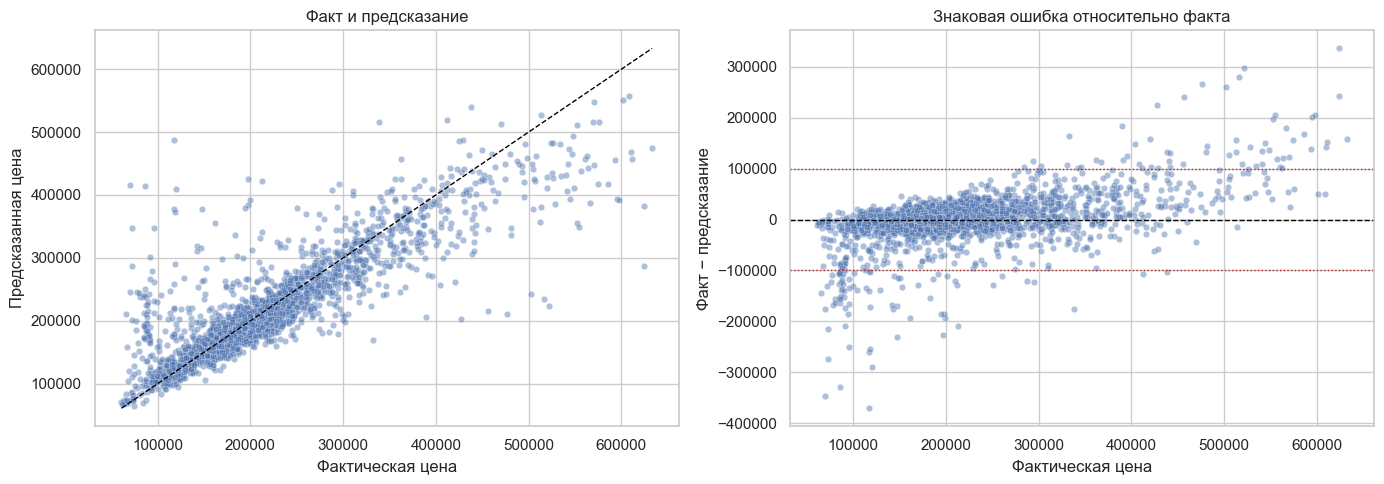

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=holdout, x="y_true", y="y_pred_cb", alpha=0.45, s=22, ax=axes[0])
price_min = min(holdout["y_true"].min(), holdout["y_pred_cb"].min())
price_max = max(holdout["y_true"].max(), holdout["y_pred_cb"].max())
axes[0].plot([price_min, price_max], [price_min, price_max], "--", color="black", linewidth=1)
axes[0].set(title="Факт и предсказание", xlabel="Фактическая цена", ylabel="Предсказанная цена")

sns.scatterplot(data=holdout, x="y_true", y="error", alpha=0.45, s=22, ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].axhline(100_000, color="firebrick", linestyle=":", linewidth=1)
axes[1].axhline(-100_000, color="firebrick", linestyle=":", linewidth=1)
axes[1].set(title="Знаковая ошибка относительно факта", xlabel="Фактическая цена", ylabel="Факт − предсказание")

plt.tight_layout()
plt.show()

## Ошибка в зависимости от площади и числа комнат

Квантили площади рассчитаны отдельно на holdout и содержат одинаковое число объектов. Для категорий с малым числом квартир результаты по числу комнат нестабильны; такие группы не следует трактовать как надёжную закономерность.

,area_group,n,MAE,median_abs_error,mean_relative_error_pct,large_error_count,large_error_pct
0,"(18.508, 40.829]",500,15476.82,11691.83,10.20,1,0.2
1,"(40.829, 47.014]",500,19208.95,12438.04,13.03,10,2.0
2,"(47.014, 58.5]",500,28426.60,15165.65,19.60,28,5.6
3,"(58.5, 72.902]",500,29013.65,17281.56,16.38,31,6.2
4,"(72.902, 212.932]",500,46888.43,25050.14,15.92,66,13.2


,Rooms,n,MAE,median_abs_error,large_error_count,large_error_pct
0,1.0,903,17903.14,11483.13,16,1.77
1,2.0,987,27731.05,16677.07,49,4.96
2,3.0,563,41050.67,22641.22,62,11.01
3,4.0,37,63449.26,41400.60,8,21.62
4,5.0,7,59514.48,54467.75,1,14.29
5,6.0,1,6315.06,6315.06,0,0.00
6,7.0,2,44038.67,44038.67,0,0.00


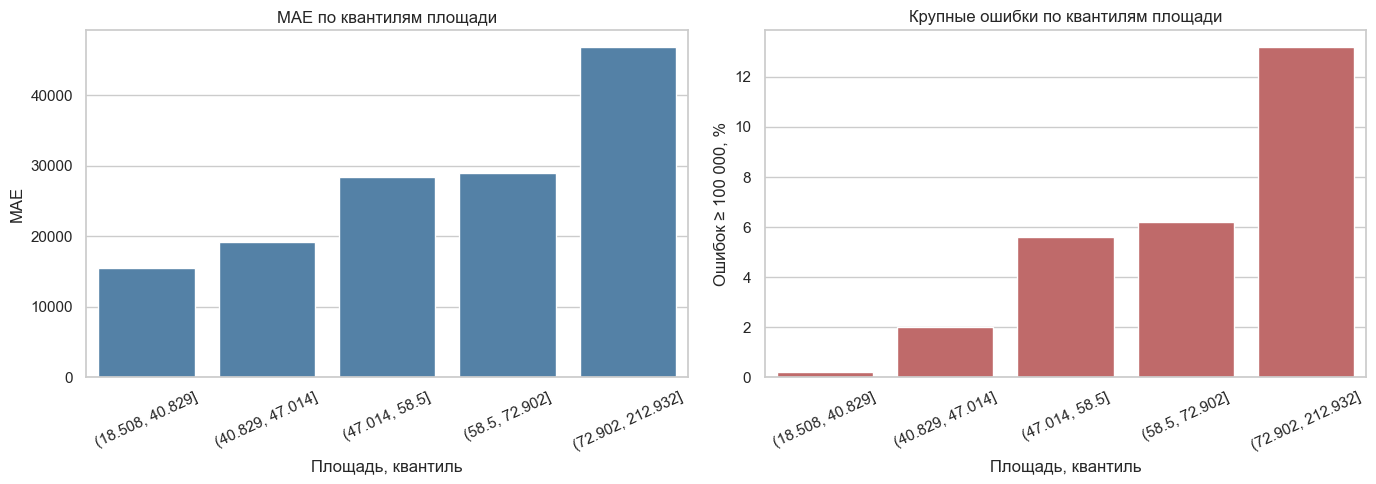

In [4]:
holdout["area_group"] = pd.qcut(holdout["Square"], q=5, duplicates="drop")

area_summary = holdout.groupby("area_group", observed=True).agg(
    n=("abs_error", "size"),
    MAE=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
    mean_relative_error_pct=("relative_error_pct", "mean"),
    large_error_count=("large_error", "sum"),
    large_error_pct=("large_error", "mean"),
).reset_index()
area_summary["large_error_pct"] *= 100
display(area_summary.round(2))

room_summary = holdout.groupby("Rooms", observed=True).agg(
    n=("abs_error", "size"),
    MAE=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
    large_error_count=("large_error", "sum"),
    large_error_pct=("large_error", "mean"),
).reset_index()
room_summary["large_error_pct"] *= 100
display(room_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=area_summary, x="area_group", y="MAE", color="steelblue", ax=axes[0])
axes[0].tick_params(axis="x", rotation=25)
axes[0].set(title="MAE по квантилям площади", xlabel="Площадь, квантиль", ylabel="MAE")
sns.barplot(data=area_summary, x="area_group", y="large_error_pct", color="indianred", ax=axes[1])
axes[1].tick_params(axis="x", rotation=25)
axes[1].set(title="Крупные ошибки по квантилям площади", xlabel="Площадь, квантиль", ylabel="Ошибок ≥ 100 000, %")
plt.tight_layout()
plt.show()

## Самые большие расхождения на holdout

Таблица отсортирована по абсолютной ошибке. Она нужна для адресной проверки исходных записей; сама по себе не доказывает, что в них есть ошибки данных.

In [5]:
outlier_columns = [
    "DistrictId", "Rooms", "Square", "Floor", "HouseFloor", "HouseYear",
    "y_true", "y_pred_cb", "error", "relative_error_pct",
]
largest_errors = holdout.nlargest(15, "abs_error")[outlier_columns].copy()
display(largest_errors.round(2))

,DistrictId,Rooms,Square,Floor,HouseFloor,HouseYear,y_true,y_pred_cb,error,relative_error_pct
9073,109,3.0,76.75,15,17.0,1996,117242.42,487911.75,-370669.33,316.16
9803,189,2.0,54.75,2,4.0,1917,69623.75,415599.30,-345975.55,496.92
9130,162,3.0,93.82,6,6.0,1952,624008.56,287554.70,336453.86,53.92
7798,20,2.0,57.26,14,17.0,2002,86108.84,415064.06,-328955.22,382.02
8144,30,1.0,117.37,14,40.0,2011,521829.56,223746.05,298083.51,57.12
9665,109,2.0,56.13,10,17.0,2001,120035.84,409017.25,-288981.41,240.75
7647,95,1.0,46.25,5,5.0,1977,516315.78,235223.00,281092.78,54.44
8209,95,2.0,57.85,8,14.0,1987,72435.02,346970.50,-274535.48,379.01
9609,30,1.0,105.62,14,39.0,2010,476843.94,210817.83,266026.11,55.79
9150,62,3.0,156.64,1,3.0,2005,502523.56,241736.42,260787.14,51.90


## Выводы

- **Есть связь абсолютной ошибки с размером квартиры.** В пяти равных по числу объектов группах площади MAE растёт примерно с **15,5 тыс.** в самой маленькой до **46,9 тыс.** в самой большой; доля ошибок ≥ 100 тыс. — с **1 из 500** до **66 из 500**. Это заметная описательная закономерность на holdout, но она не объясняет причины ошибок и может быть связана с большей вариативностью цен на крупные квартиры.
- **Большие ошибки возникают в обоих направлениях.** На holdout найдено **136 из 2 500 (5,44%)** расхождений не менее 100 тыс.: в **59** случаях модель недооценила цену, в **77** — переоценила. Следовательно, однонаправленной общей ошибки нет.
- **Для квартир с большим числом комнат абсолютная ошибка в среднем выше**, однако групп 4+ комнат мало. Это наблюдение слабее эффекта площади и требует проверки на большей выборке.
- В крайних примерах встречаются оба типа промаха: например, цена **69,6 тыс.** при предсказании **415,6 тыс.** и цена **624,0 тыс.** при предсказании **287,6 тыс.** По доступным признакам нельзя заключить, что это ошибки данных или единый систематический фактор; такие записи стоит сверить с источником и исследовать дополнительные признаки.

**Итог:** наиболее устойчивый сигнал — рост абсолютной ошибки и частоты очень больших ошибок с площадью. Другой подтверждённой общей закономерности, которая объясняла бы отдельные сильные расхождения, в этих данных нет. Выводы описательные: для проверки причин потребуются дополнительные признаки/исходные записи и отдельная проверочная выборка.